In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import poisson

#### Calibration:

In [52]:
#loading files for calibration:
cal005 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_0-5mus.txt')
cal02 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_2mus.txt')
cal03 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_3mus.txt')
cal04 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_4mus.txt')
cal05 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_5mus.txt')
cal06 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_6mus.txt')
cal07 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_7mus.txt')
cal08 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_8mus.txt')
cal09 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/calibration/cal_9mus.txt')

calibration_dfs = [cal005, cal02, cal03, cal04, cal05, cal06, cal07, cal08, cal09]

In [45]:
#defining a function to find the channel in which the peak occurs, and the width on either side for errors
def get_channel_err(df):
    peak = np.max(df['0'])
    channel_no = np.where(df['0']==peak)[0][0]

    peak_area = df[df['0']>0]

    low_err = channel_no - peak_area.index[0]
    high_err = peak_area.index[-1] - channel_no

    return channel_no, low_err, high_err
    

In [46]:
channels = []
cal_low_errs = []
cal_high_errs = []

for df in calibration_dfs:
    channel_no, low_err, high_err = get_channel_err(df)
    channels.append(channel_no)
    cal_low_errs.append(low_err)
    cal_high_errs.append(high_err)

times = [0.5, 2, 3, 4, 5, 6, 7, 8, 9]

In [47]:
#taking mean of asymmetric peak width error, as symmetric errror needed for fitting
means = []
for x, y in zip(cal_low_errs, cal_high_errs):
    means.append(x+y/2)

In [48]:
#fitting a calibration line to the data
def lin(x, a, b):
    return a*x + b

popt, pcov = curve_fit(lin, channels, times, sigma=means)
a_time, b_time = popt
a_err, b_err = np.sqrt(np.diag(pcov))
print(a_time, b_time)

0.0025127520906402002 -0.03913971725302579


Text(0, 0.5, 'Time ($\\mu$s)')

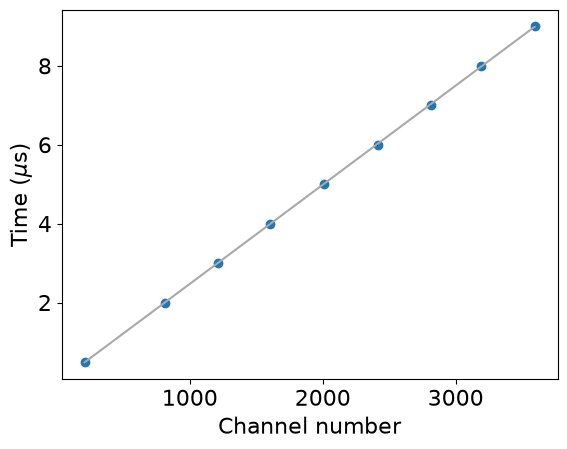

In [49]:
#plotting calibration line
fig, ax = plt.subplots()

ax.scatter(channels, times)

cal_err = [cal_low_errs, cal_high_errs]
ax.errorbar(channels, times, xerr = cal_err, fmt='None', color='black')

plt.plot(channels, lin(np.array(channels), a_time, b_time), color='darkgray')

ax.set_xlabel('Channel number')
ax.set_ylabel(r'Time ($\mu$s)')

In [50]:
def channel_time(channel_no):
    return a_time*channel_no + b_time

def time_channel(time):
    return (time - b_time)/a_time

#finding temporal width of channels
twidth = channel_time(4096)/4096
twidth_err = np.sqrt(a_err**2+b_err**2)

print(twidth, twidth_err)

0.0025031964956077233 0.007596350892967363


#### Run 1 analysis:

In [8]:
#defining a decay function to fit to the data, with b = lifetime, c = constant background term 
def decay(x, a, b, c):
    return a*np.exp(-x/b) + c

In [9]:
data1 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/thurs_15_0115.txt', header=None)

In [10]:
data1.index = channel_time(data1.index)

In [11]:
#rebinning data so that expected counts >10 per bin
channels = np.array(data1.index)
counts = data1[0].values

bin_centres = []
bin_averages = []
expected_averages = []

#expected counts calculated from literature lifetime and other parameters fit by eye to decay
exp=decay(channels, 60, 2.197, 2)

i = len(channels)-1
while i>0:
    exp_totals = exp[i]
    count_totals = counts[i]
    n=0
    #combining channels until expected is >10
    while exp_totals<10:
        n+=1
        exp_totals+=exp[i-n]
        count_totals+=counts[i-n]
    
    #taking average and centre value if bin encompasses more than one channel, 
    #otherwise taking channel and count as normal
    if n>0:
        bin_centres.append((channels[i] + channels[i-n])/2)
        bin_averages.append(count_totals/(n+1))
        expected_averages.append(exp_totals/(n+1))
    else:
        bin_centres.append(channels[i])
        bin_averages.append(count_totals)
        expected_averages.append(exp_totals)
    i-=n+1

In [12]:
data1_binned = pd.DataFrame({'bin_centre':bin_centres, 'bin_avg':bin_averages, 
                             'expected_avg':expected_averages})
data1_binned.set_index('bin_centre', inplace=True)

In [13]:
#cutting first few channels by eye to get a desire fit
data_fit = data1_binned[data1_binned.index>channel_time(70)]

In [54]:
#fitting preliminary curve so that peak can be removed
popt, pcov = curve_fit(decay, data_fit.index, data_fit['bin_avg'], p0 = [1, 1, 1], 
                      sigma=np.sqrt(data_fit['expected_avg'].values))
a_prelimfit, b_prelimfit, c_prelimfit = popt
a_prelimfit_err, b_prelimfit_err, c_prelimfit_err = np.sqrt(np.diag(pcov))

In [55]:
print(a_prelimfit, b_prelimfit, c_prelimfit)

58.71373982888074 2.1535569569425888 1.843537932157304


In [56]:
print(a_prelimfit_err, b_prelimfit_err, c_prelimfit_err)

0.4404509459146034 0.02446632095236657 0.10751789747136009


In [57]:
exclude_channels = []
for index, point in zip(data1_binned.index, data1_binned['bin_avg']):
    dist = np.abs(point - decay(index, a_prelimfit, b_prelimfit, c_prelimfit))
    if dist>20:
        exclude_channels.append(index)
    if index>9.94:
        exclude_channels.append(index)

In [58]:
data1_ref = data1_binned.drop(exclude_channels)

In [59]:
popt, pcov = curve_fit(decay, np.array(data1_ref.index), data1_ref['bin_avg'].values, p0 = [1, 1, -1], 
                       sigma = np.sqrt(data1_ref['expected_avg'].values))
a1, b1, c1 = popt
a1_err, b1_err, c1_err = np.sqrt(np.diag(pcov))
print(a1, b1, c1)
print(a1_err, b1_err, c1_err)

59.01357247444953 2.097627368714904 2.1900034794459993
0.4375516079477065 0.023734754587873122 0.10837825070261944


In [20]:
plt.rcParams.update({'font.size': 16})

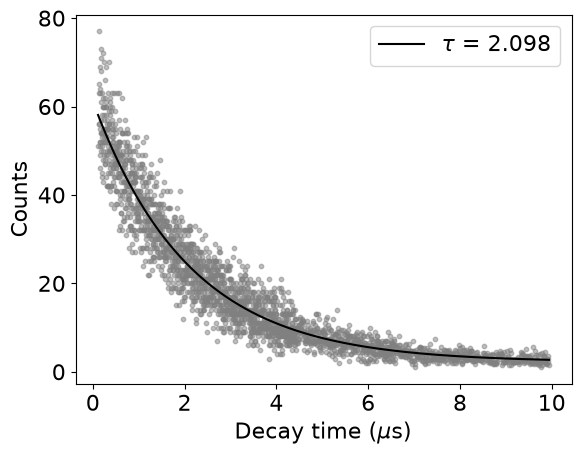

In [21]:
plt.scatter(data1_ref.index, data1_ref['bin_avg'], s=10, color='gray', alpha=0.5)
plt.plot(data1_ref.index, decay(data1_ref.index, a1, b1, c1), color='black', 
         label=r'$\tau$ = '+str(np.round(b1, decimals=3)))
plt.xlabel(r'Decay time ($\mu$s)')
plt.ylabel('Counts')
plt.legend()
plt.savefig("C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/figures/datarun1_decaycurve.png", 
            bbox_inches='tight')

In [22]:
tpos = 2.197
tneg = 2.043

In [23]:
def muonratio(tobs):
    return -(tpos/tneg)*((tneg-tobs)/(tpos-tobs))

muonratio(b1)

np.float64(0.5911601934953676)

#### Run 2 analysis:

In [25]:
#repeating process for second data run
data2 = pd.read_csv(
    'C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/data/tues_20_0049.txt', header=None)

In [26]:
data2.index = channel_time(data2.index)

In [27]:
channels = np.array(data2.index)
counts = data2[0].values

bin_lower_edges = []
bin_upper_edges = []
channel_sizes = []
bin_centres = []
bin_averages = []

exp=decay(channels, 60, 2.197, 2)

i = len(channels)-1
while i>0:
    exp_totals = exp[i]
    count_totals = counts[i]
    n=0
    while exp_totals<10:
        n+=1
        exp_totals+=exp[i-n]
        count_totals+=counts[i-n]
        
    bin_lower_edges.append(channels[i])
    bin_upper_edges.append(channels[i-n])
    channel_sizes.append(n+1)
    
    if n>0:
        bin_centres.append((channels[i] + channels[i-n])/2)
        bin_averages.append(count_totals/(n+1))
    else:
        bin_centres.append(channels[i])
        bin_averages.append(count_totals)
    i-=n+1

In [28]:
data2_binned = pd.DataFrame({'bin_centre':bin_centres, 'bin_avg':bin_averages, 
                             'expected_avg':expected_averages})
data2_binned.set_index('bin_centre', inplace=True)

In [29]:
data2_fit = data2_binned[data2_binned.index>channel_time(40)]

In [41]:
popt, pcov = curve_fit(decay, data2_fit.index, data2_fit['bin_avg'], p0 = [1, 1, 1])
a_prelimfit, b_prelimfit, c_prelimfit = popt
a_prelimfit_err, b_prelimfit_err, c_prelimfit_err = np.sqrt(np.diag(pcov))

In [31]:
exclude_channels = []
for index, point in zip(data2_binned.index, data2_binned['bin_avg']):
    dist = np.abs(point - decay(index, a_prelimfit, b_prelimfit, c_prelimfit))
    if dist>20:
        exclude_channels.append(index)
    if index>9.94:
        exclude_channels.append(index)

In [32]:
data2_ref = data2_binned.drop(exclude_channels)

In [34]:
popt, pcov = curve_fit(decay, data2_ref.index, data2_ref['bin_avg'].values, p0 = [80, 2, 2], sigma=np.sqrt(data2_ref['expected_avg']))
a2, b2, c2 = popt
a2_err, b2_err, c2_err = np.sqrt(np.diag(pcov))
print(a2, b2, c2)
print(a2_err, b2_err, c2_err)

33.473477914558515 2.0356172199009457 4.943577737598522
0.3905804961105231 0.03660866147935818 0.09787338173743897


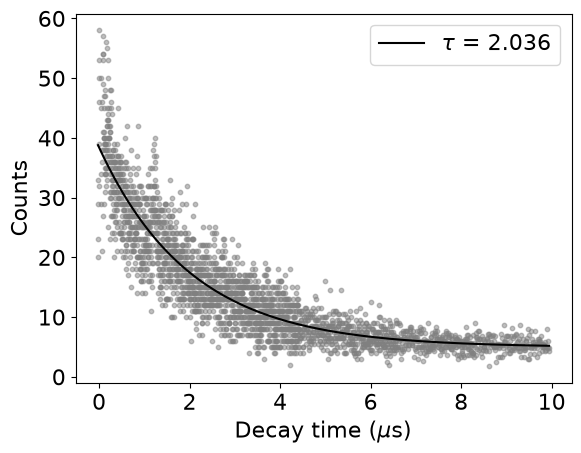

In [35]:
plt.scatter(data2_ref.index, data2_ref['bin_avg'].values, s=10, color='gray', alpha=0.5)
plt.plot(data2_ref.index, decay(data2_ref.index, a2, b2, c2), color='black', label=r'$\tau$ = '+str(np.round(b2, decimals=3)))
plt.xlabel(r'Decay time ($\mu$s)')
plt.ylabel('Counts')
plt.legend()
plt.savefig("C:/Users/dearb/Documents/UCD_labs/fourth_year_labs/muon_detector/figures/datarun2_decaycurve.png", bbox_inches='tight')